In [5]:
import pandas as pd
import numpy as np
read=pd.read_csv("/home/upain/Downloads/customer_complaints_dataset.csv")
read.head()       # it show 1st five rows
read.tail()       # it display last five rows


,complaint,category
715,I cannot download my payment receipt Can you h...,Billing
716,Please help: The product does not match the de...,Product / Refund
717,Please help: I want a replacement for the faul...,Product / Refund
718,Please help: The website shows an error every ...,Technical Support
719,"Hello, The website shows an error every time I...",Technical Support


In [6]:
read.tail()       # it display last five rows


,complaint,category
715,I cannot download my payment receipt Can you h...,Billing
716,Please help: The product does not match the de...,Product / Refund
717,Please help: I want a replacement for the faul...,Product / Refund
718,Please help: The website shows an error every ...,Technical Support
719,"Hello, The website shows an error every time I...",Technical Support


In [7]:
read.shape      # it display the shape of the data (rows n columns )

(720, 2)

In [8]:
read.isnull().sum()

complaint    0
category     0
dtype: int64

In [9]:
print(read.columns)

Index(['complaint', 'category'], dtype='str')


In [10]:
read.info() # it helps to undersatnd the structure of the dataset

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   complaint  720 non-null    str  
 1   category   720 non-null    str  
dtypes: str(2)
memory usage: 11.4 KB


In [11]:
read.isnull().sum() # it counts the missing value

complaint    0
category     0
dtype: int64

In [12]:
read.isnull().mean()

complaint    0.0
category     0.0
dtype: float64

In [13]:
read.duplicated().sum() # count the duplicated rows

np.int64(100)

In [14]:
read[read.duplicated()] # display the duplicated rows

,complaint,category
99,I am contacting you because My payment was ded...,Billing
119,Can someone check? There is an unexpected tran...,Billing
121,I am unhappy because My package arrived later ...,Delivery
135,I am unhappy because The account login page is...,Technical Support
144,I am unhappy because I cannot download my paym...,Billing
...,...,...
705,I need assistance: I cannot access my account ...,Technical Support
706,I am contacting you because The box arrived bu...,Product / Refund
710,Please help: The product stopped working after...,Product / Refund
711,I am unhappy because The website does not load...,Technical Support


In [15]:
read=read.drop_duplicates() # remove duplicates

In [16]:
read.duplicated().sum()  # here we can check the duplicated rows in our dataset

np.int64(0)

In [17]:
read.describe()

,complaint,category
count,620,620
unique,620,4
top,I am unhappy because The invoice amount is wro...,Product / Refund
freq,1,157


In [18]:
read.groupby("complaint")["category"].nunique().sort_values(ascending=False)

complaint
Can someone check? I cannot access my account Can you help me?                  1
Can someone check? I cannot access my account Thank you.                        1
Can someone check? I cannot download my payment receipt Thank you.              1
Can someone check? I cannot download my payment receipt as soon as possible.    1
Can someone check? I cannot download my payment receipt please.                 1
                                                                               ..
The subscription renewal charged me incorrectly please.                         1
The subscription renewal charged me incorrectly.                                1
The website does not load on my browser This is frustrating.                    1
The website does not load on my browser as soon as possible.                    1
Tracking information has not updated This is frustrating.                       1
Name: category, Length: 620, dtype: int64

In [19]:
category_count = read["category"].value_counts()
print(category_count)                            # category count class wise



category
Product / Refund     157
Technical Support    156
Billing              154
Delivery             153
Name: count, dtype: int64


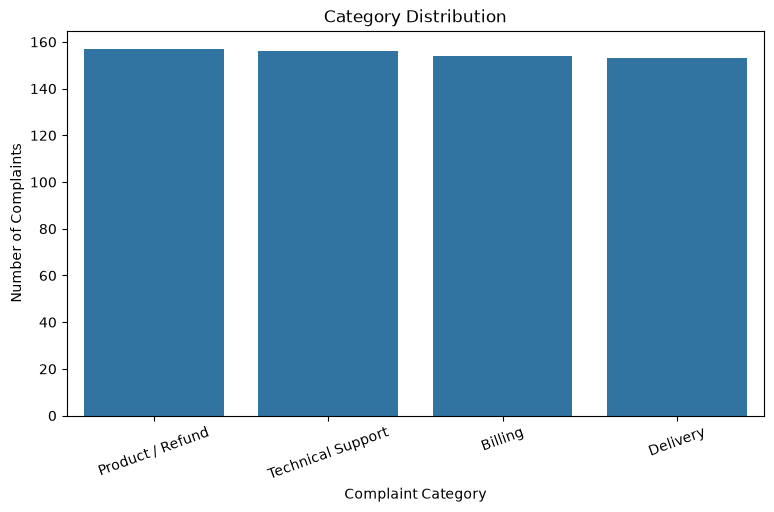

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))                          # it shows diffrence between alll the class and how balanced the data

sns.countplot(
    data=read,
    x="category",
    order=read["category"].value_counts().index
)

plt.title("Category Distribution")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=20)

plt.show()

In [21]:
read["text_length"] = read["complaint"].str.len()
read["text_length"].describe()

count    620.000000
mean      66.559677
std       13.428491
min       26.000000
25%       57.750000
50%       67.000000
75%       76.000000
max      104.000000
Name: text_length, dtype: float64

In [22]:
read.groupby("category")["text_length"].apply(list)

category
Billing              [56, 74, 68, 63, 72, 60, 63, 63, 76, 54, 81, 7...
Delivery             [77, 50, 74, 76, 52, 44, 85, 72, 46, 81, 38, 5...
Product / Refund     [45, 69, 83, 68, 71, 58, 88, 42, 51, 47, 87, 5...
Technical Support    [66, 79, 68, 74, 66, 83, 66, 61, 46, 69, 61, 8...
Name: text_length, dtype: object

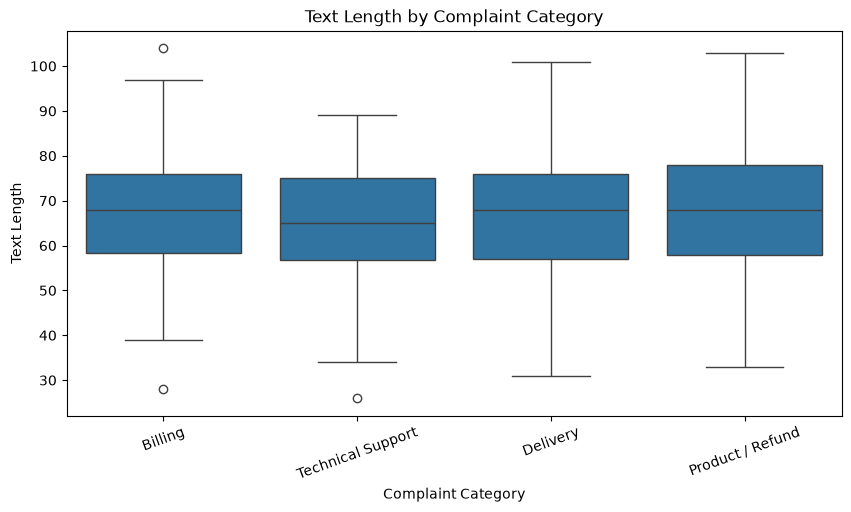

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=read,
    x="category",
    y="text_length"
)

plt.title("Text Length by Complaint Category")
plt.xlabel("Complaint Category")
plt.ylabel("Text Length")
plt.xticks(rotation=20)

plt.show()

In [24]:
X = read["complaint"]
y = read["category"]

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [27]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Billing','Delivery','Product / Refund','Technical Support']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None

In [28]:
y_pred = model.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 1.0
                   precision    recall  f1-score   support

          Billing       1.00      1.00      1.00        31
         Delivery       1.00      1.00      1.00        31
 Product / Refund       1.00      1.00      1.00        31
Technical Support       1.00      1.00      1.00        31

         accuracy                           1.00       124
        macro avg       1.00      1.00      1.00       124
     weighted avg       1.00      1.00      1.00       124



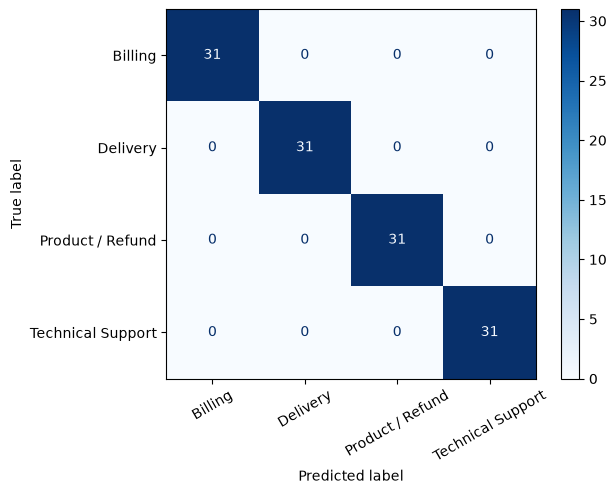

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", xticks_rotation=30)

In [31]:
# Calculate and print both training and test accuracy
y_train_pred = model.predict(X_train)
print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Train Accuracy: 1.0
Test Accuracy: 1.0


In [32]:
print("Training:", model.score(X_train, y_train))
print("Testing:", model.score(X_test, y_test))

Training: 1.0
Testing: 1.0


In [33]:
new_complaints = [
    "My bank charged me twice",
    "My parcel is still missing",
    "The application crashes whenever I open it",
    "I want my money back for a damaged item"
]

model.predict(new_complaints)

array(['Billing', 'Product / Refund', 'Technical Support',
       'Product / Refund'], dtype=object)

In [34]:
import joblib

joblib.dump(model, "complaint_model.pkl")

['complaint_model.pkl']